# Zomato Restaurant Analysis

## Project Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on Zomato restaurant data to identify patterns and insights related to restaurant ratings, cuisines, locations, pricing, online delivery, and customer preferences.

### Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import sys
print(sys.executable)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
import seaborn
print(seaborn.__version__)

0.13.2


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv(
    "../datasets/zomato/zomato.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 9551
Columns: 21


In [6]:
df.columns.tolist()

['Restaurant ID',
 'Restaurant Name',
 'Country Code',
 'City',
 'Address',
 'Locality',
 'Locality Verbose',
 'Longitude',
 'Latitude',
 'Cuisines',
 'Average Cost for two',
 'Currency',
 'Has Table booking',
 'Has Online delivery',
 'Is delivering now',
 'Switch to order menu',
 'Price range',
 'Aggregate rating',
 'Rating color',
 'Rating text',
 'Votes']

In [7]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## Data Quality Analysis

Before performing exploratory data analysis, the dataset is checked for missing values, duplicate records, data types, and basic statistical characteristics to ensure data quality and reliability.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [9]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
Cuisines    9
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
print("Unique restaurants:", df["Restaurant Name"].nunique())
print("Unique cities:", df["City"].nunique())
print("Unique cuisines:", df["Cuisines"].nunique())

Unique restaurants: 7446
Unique cities: 141
Unique cuisines: 1825


In [12]:
df[[
    "Average Cost for two",
    "Price range",
    "Aggregate rating",
    "Votes"
]].describe()

,Average Cost for two,Price range,Aggregate rating,Votes
count,9551.000000,9551.000000,9551.000000,9551.000000
mean,1199.210763,1.804837,2.666370,156.909748
std,16121.183073,0.905609,1.516378,430.169145
min,0.000000,1.000000,0.000000,0.000000
25%,250.000000,1.000000,2.500000,5.000000
50%,400.000000,2.000000,3.200000,31.000000
75%,700.000000,2.000000,3.700000,131.000000
max,800000.000000,4.000000,4.900000,10934.000000


## Data Cleaning

The dataset is cleaned by handling missing values, checking categorical consistency, investigating unusual numerical values, and removing unnecessary fields only when justified.

In [13]:
df[df["Cuisines"].isnull()]

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
84,17284105,Cookie Shoppe,216,Albany,"115 N Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.154000,31.577200,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,34
87,17284211,Pearly's Famous Country Cookng,216,Albany,"814 N Slappey Blvd, Albany, GA 31701",Albany,"Albany, Albany",-84.175900,31.588200,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,36
94,17284158,Jimmie's Hot Dogs,216,Albany,"204 S Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.153400,31.575100,NaN,...,Dollar($),No,No,No,No,1,3.9,Yellow,Good,160
297,17374552,Corkscrew Cafe,216,Gainesville,"51 W Main St, Dahlonega, GA 30533",Dahlonega,"Dahlonega, Gainesville",-83.985800,34.531800,NaN,...,Dollar($),No,No,No,No,3,3.9,Yellow,Good,209
328,17501439,Dovetail,216,Macon,"543 Cherry St, Macon, GA 31201",Macon,"Macon, Macon",-83.627979,32.836410,NaN,...,Dollar($),No,No,No,No,3,3.8,Yellow,Good,102
346,17606621,HI Lite Bar & Lounge,216,Miller,"109 N Broadway Ave, Miller, SD 57362",Miller,"Miller, Miller",-98.989100,44.515800,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,11
368,17059060,Hillstone,216,Orlando,"215 South Orlando Avenue, Winter Park, FL 32789",Winter Park,"Winter Park, Orlando",-81.365260,28.596682,NaN,...,Dollar($),No,No,No,No,3,4.4,Green,Very Good,1158
418,17142698,Leonard's Bakery,216,Rest of Hawaii,"933 Kapahulu Ave, Honolulu, HI 96816",Kaimuki,"Kaimuki, Rest of Hawaii",-157.813432,21.284586,NaN,...,Dollar($),No,No,No,No,1,4.7,Dark Green,Excellent,707
455,17616465,Tybee Island Social Club,216,Savannah,"1311 Butler Ave, Tybee Island, GA 31328",Tybee Island,"Tybee Island, Savannah",-80.848297,31.995810,NaN,...,Dollar($),No,No,No,No,1,3.9,Yellow,Good,309


In [14]:
df.nlargest(10, "Average Cost for two")[
    [
        "Restaurant Name",
        "City",
        "Average Cost for two",
        "Currency",
        "Price range",
        "Aggregate rating"
    ]
]

,Restaurant Name,City,Average Cost for two,Currency,Price range,Aggregate rating
9283,Skye,Jakarta,800000,Indonesian Rupiah(IDR),3,4.1
9284,Satoo - Hotel Shangri-La,Jakarta,800000,Indonesian Rupiah(IDR),3,4.6
9287,Sushi Masa,Jakarta,500000,Indonesian Rupiah(IDR),3,4.9
9289,3 Wise Monkeys,Jakarta,450000,Indonesian Rupiah(IDR),3,4.2
9294,Avec Moi Restaurant and Bar,Jakarta,350000,Indonesian Rupiah(IDR),3,4.3
9288,Lucky Cat Coffee & Kitchen,Jakarta,300000,Indonesian Rupiah(IDR),3,4.3
9295,Onokabe,Tangerang,300000,Indonesian Rupiah(IDR),3,3.7
9278,Lemongrass,Bogor,250000,Indonesian Rupiah(IDR),3,4.0
9285,MONKS,Jakarta,250000,Indonesian Rupiah(IDR),3,4.2
9279,Talaga Sampireun,Jakarta,200000,Indonesian Rupiah(IDR),3,4.9


In [15]:
df["Currency"].value_counts()

Currency
Indian Rupees(Rs.)        8652
Dollar($)                  482
Pounds(£)                  80
Brazilian Real(R$)          60
Rand(R)                     60
Emirati Diram(AED)          60
NewZealand($)               40
Turkish Lira(TL)            34
Botswana Pula(P)            22
Indonesian Rupiah(IDR)      21
Qatari Rial(QR)             20
Sri Lankan Rupee(LKR)       20
Name: count, dtype: int64

In [16]:
df_clean = df.copy()

print("Original rows:", len(df_clean))

Original rows: 9551


In [17]:
df_clean = df_clean.dropna(subset=["Cuisines"])

print("Rows after removing missing cuisines:", len(df_clean))

Rows after removing missing cuisines: 9542


In [18]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Missing values after cleaning:
Series([], dtype: int64)


In [19]:
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows after cleaning: 0


In [20]:
df_clean["Country Code"].value_counts().head()

Country Code
1      8652
216     425
215      80
30       60
189      60
Name: count, dtype: int64

In [21]:
df_india = df_clean[df_clean["Country Code"] == 1].copy()

print("Indian restaurants:", len(df_india))

Indian restaurants: 8652


In [22]:
df_india["Currency"].value_counts()

Currency
Indian Rupees(Rs.)    8652
Name: count, dtype: int64

In [23]:
print("Rows after removing missing cuisines:", len(df_clean))

Rows after removing missing cuisines: 9542


In [24]:
print("Indian restaurants:", len(df_india))

Indian restaurants: 8652


## Exploratory Data Analysis

Exploratory Data Analysis is performed to identify patterns, trends, distributions, and relationships in the restaurant data.

In [25]:
city_counts = df_clean["City"].value_counts().head(10)

print(city_counts)

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Ahmedabad         21
Lucknow           21
Guwahati          21
Amritsar          21
Name: count, dtype: int64


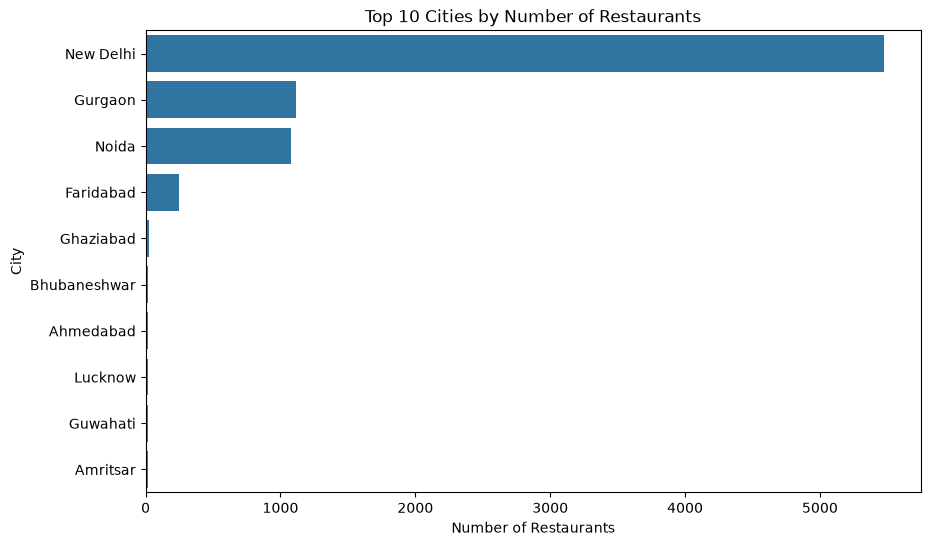

In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_counts.values,
    y=city_counts.index
)

plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.show()

In [27]:
cuisine_counts = df_clean["Cuisines"].value_counts().head(10)

print(cuisine_counts)

Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64


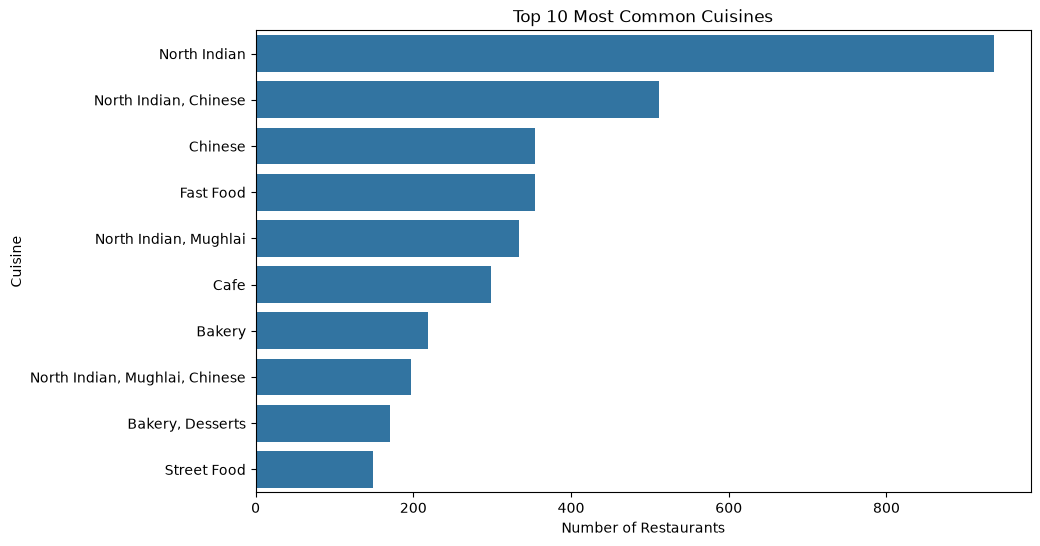

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=cuisine_counts.values,
    y=cuisine_counts.index
)

plt.title("Top 10 Most Common Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")

plt.show()

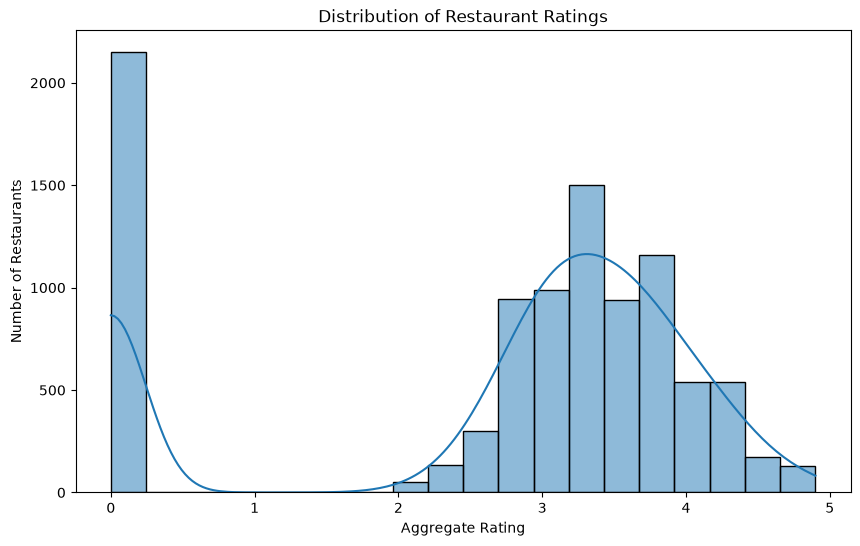

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df_clean["Aggregate rating"],
    bins=20,
    kde=True
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.show()

In [30]:
rating_counts = df_clean["Rating text"].value_counts()

print(rating_counts)

Rating text
Average      3734
Not rated    2148
Good         2096
Very Good    1078
Excellent     300
Poor          186
Name: count, dtype: int64


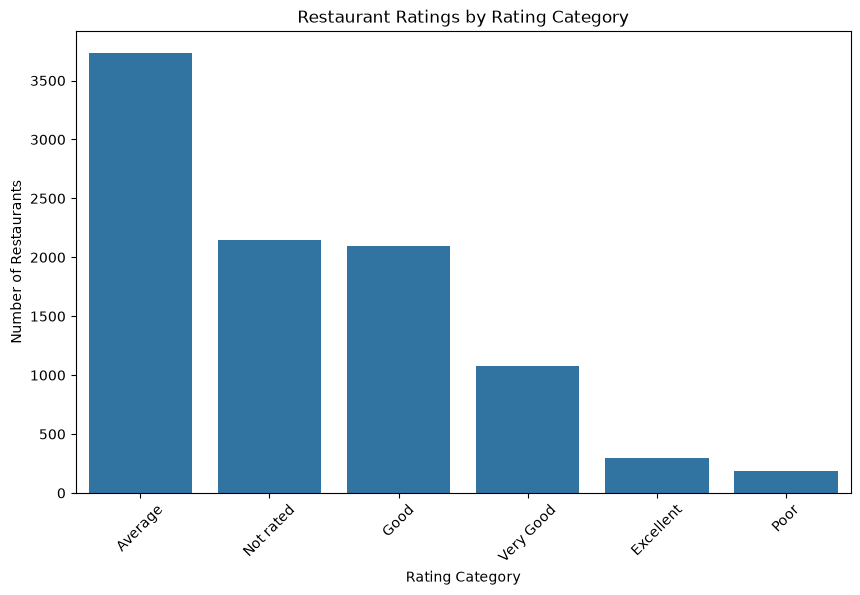

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Restaurant Ratings by Rating Category")
plt.xlabel("Rating Category")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.show()

### Key Insights

1. New Delhi has the highest number of restaurant listings in the dataset, followed by Gurgaon and Noida, showing a strong concentration of records in the Delhi-NCR region.

2. North Indian cuisine is the most frequently listed cuisine, followed by North Indian-Chinese combinations and Chinese/Fast Food restaurants.

3. The "Average" rating category contains the largest number of restaurants.

4. A significant number of restaurants are marked as "Not rated", indicating limited rating information for those establishments.

5. The analysis represents the restaurants available in the dataset and should not be interpreted as a complete representation of the entire restaurant industry.

In [32]:
price_counts = df_india["Price range"].value_counts().sort_index()

print(price_counts)

Price range
1    4295
2    2858
3    1111
4     388
Name: count, dtype: int64


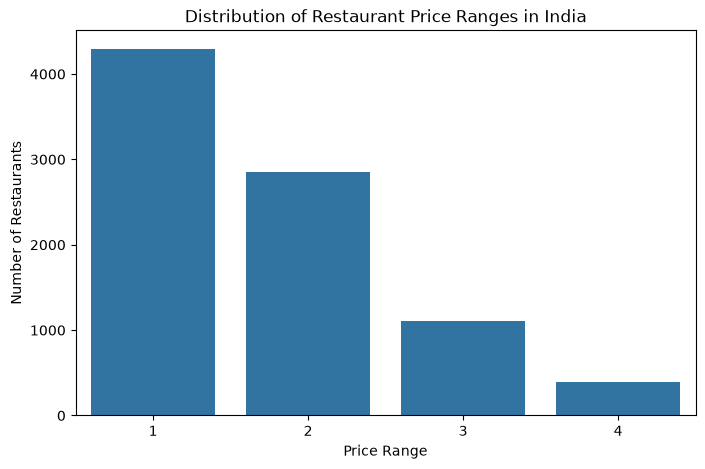

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=price_counts.index,
    y=price_counts.values
)

plt.title("Distribution of Restaurant Price Ranges in India")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")

plt.show()

In [34]:
price_cost = df_india.groupby("Price range")["Average Cost for two"].mean()

print(price_cost)

Price range
1     284.384168
2     620.125962
3    1257.875788
4    2582.860825
Name: Average Cost for two, dtype: float64


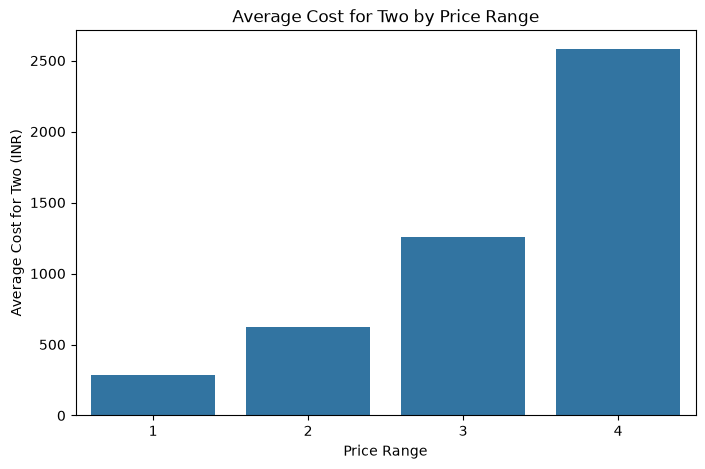

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=price_cost.index,
    y=price_cost.values
)

plt.title("Average Cost for Two by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Cost for Two (INR)")

plt.show()

### Pricing Insights

1. Price Range 1 has the highest number of restaurants, indicating that budget-friendly restaurants dominate the Indian listings in this dataset.

2. The average cost for two increases consistently across price ranges, from approximately ₹284 in Price Range 1 to ₹2,583 in Price Range 4.

3. Premium restaurants (Price Range 4) represent a relatively small portion of the dataset compared with budget restaurants.

4. The consistent increase in average cost across price ranges indicates that the price-range classification is reasonably aligned with restaurant spending levels.

In [36]:
rating_by_price = df_india.groupby("Price range")["Aggregate rating"].mean()

print(rating_by_price)

Price range
1    1.932107
2    2.855108
3    3.569307
4    3.628866
Name: Aggregate rating, dtype: float64


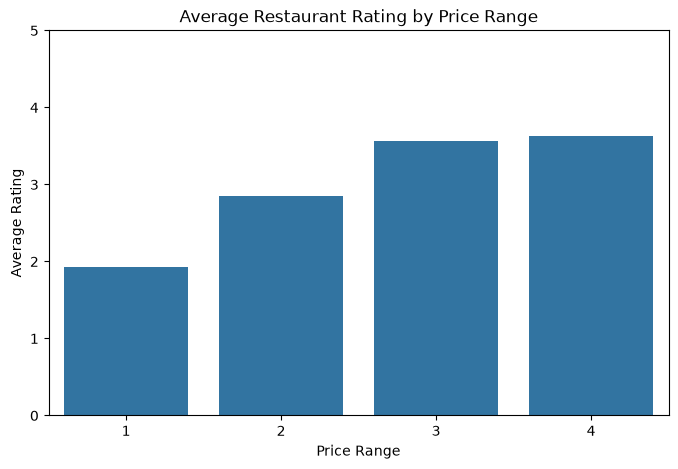

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_by_price.index,
    y=rating_by_price.values
)

plt.title("Average Restaurant Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")

plt.ylim(0, 5)

plt.show()

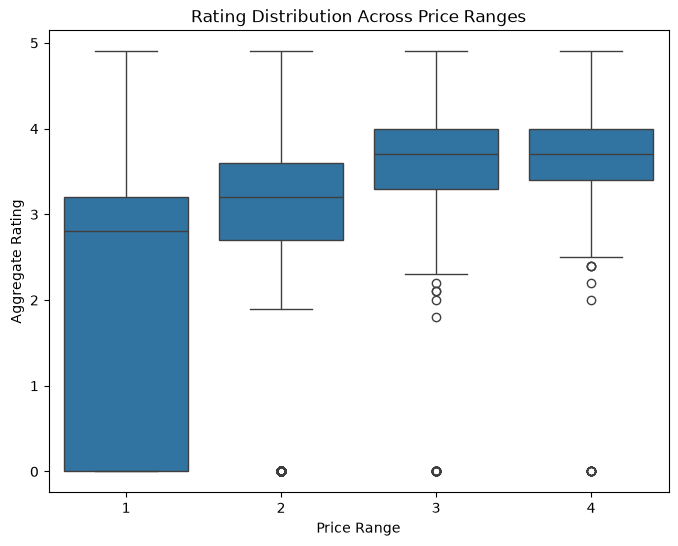

In [38]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x="Price range",
    y="Aggregate rating",
    data=df_india
)

plt.title("Rating Distribution Across Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Aggregate Rating")

plt.show()

In [39]:
rating_by_price

Price range
1    1.932107
2    2.855108
3    3.569307
4    3.628866
Name: Aggregate rating, dtype: float64

### Price vs Rating Insights

1. Restaurants in higher price ranges have higher average ratings in this dataset.

2. The average rating increases from 1.93 for Price Range 1 to 3.63 for Price Range 4.

3. This indicates a positive association between restaurant price range and average rating.

4. However, this analysis shows association rather than causation, as other factors may also influence restaurant ratings.

In [40]:
top_voted = df_clean.nlargest(10, "Votes")[
    ["Restaurant Name", "City", "Aggregate rating", "Votes"]
]

top_voted

,Restaurant Name,City,Aggregate rating,Votes
728,Toit,Bangalore,4.8,10934
735,Truffles,Bangalore,4.7,9667
3994,Hauz Khas Social,New Delhi,4.3,7931
2412,Peter Cat,Kolkata,4.3,7574
739,AB's - Absolute Barbecues,Bangalore,4.6,6907
2414,Barbeque Nation,Kolkata,4.9,5966
743,Big Brewsky,Bangalore,4.5,5705
2307,AB's - Absolute Barbecues,Hyderabad,4.9,5434
736,The Black Pearl,Bangalore,4.1,5385
2411,BarBQ,Kolkata,4.2,5288


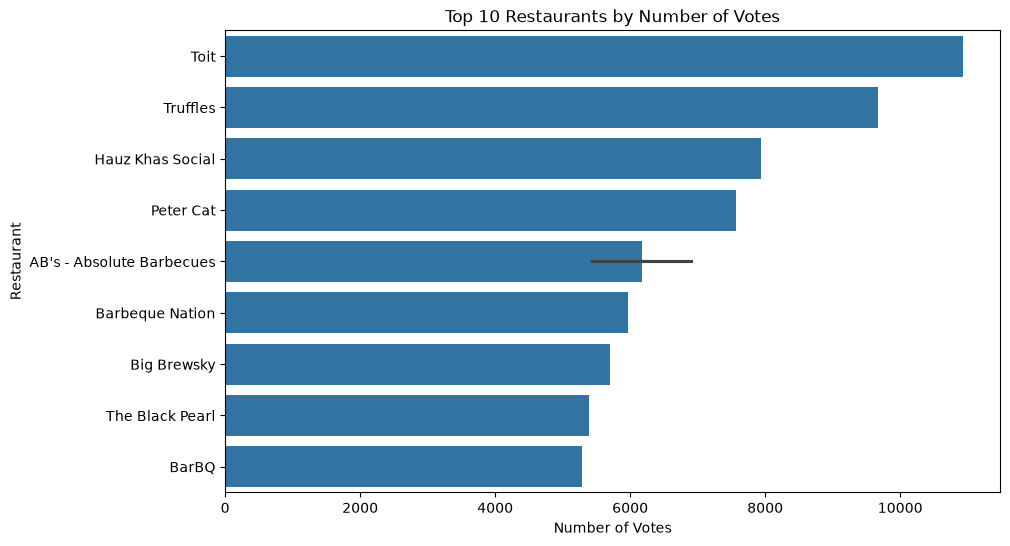

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_voted,
    x="Votes",
    y="Restaurant Name"
)

plt.title("Top 10 Restaurants by Number of Votes")
plt.xlabel("Number of Votes")
plt.ylabel("Restaurant")

plt.show()

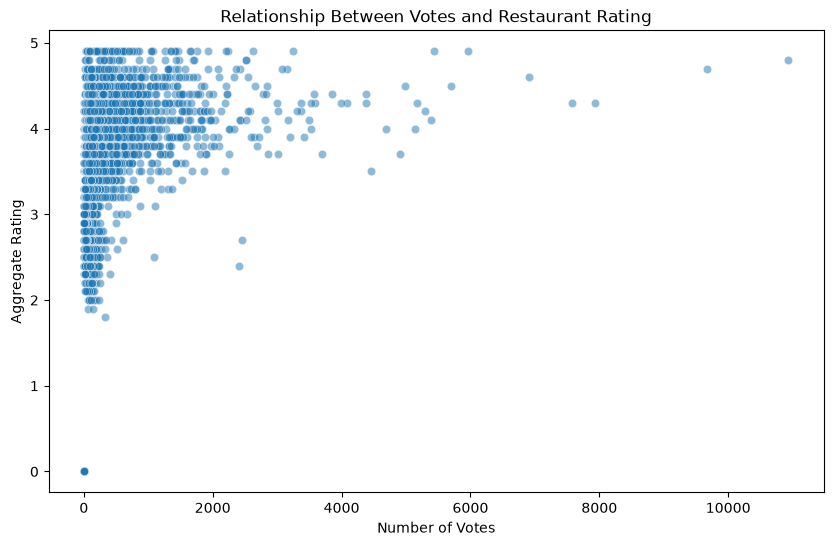

In [42]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Votes",
    y="Aggregate rating",
    alpha=0.5
)

plt.title("Relationship Between Votes and Restaurant Rating")
plt.xlabel("Number of Votes")
plt.ylabel("Aggregate Rating")

plt.show()

### Customer Engagement Insights

1. Toit in Bangalore has the highest number of votes in the dataset, with 10,934 votes and an aggregate rating of 4.8.

2. Bangalore has a strong presence among the most-voted restaurants.

3. Restaurants with a high number of votes do not necessarily have the highest ratings, showing that customer engagement and customer satisfaction are different measures.

4. The number of votes can be used as an indicator of customer engagement, while aggregate rating represents customer satisfaction.

In [43]:
correlation = df_clean["Votes"].corr(df_clean["Aggregate rating"])

print("Correlation between Votes and Rating:", correlation)

Correlation between Votes and Rating: 0.31347418032500063


### Votes vs Rating Insights

1. The correlation between customer votes and aggregate rating is approximately 0.313.

2. This indicates a weak-to-moderate positive relationship between customer engagement and restaurant rating.

3. Restaurants with more votes tend to have somewhat higher ratings, but the relationship is not strong.

4. Correlation does not imply causation, so the analysis does not indicate that a higher number of votes causes better ratings.

In [44]:
delivery_counts = df_clean["Has Online delivery"].value_counts()

print(delivery_counts)

Has Online delivery
No     7091
Yes    2451
Name: count, dtype: int64


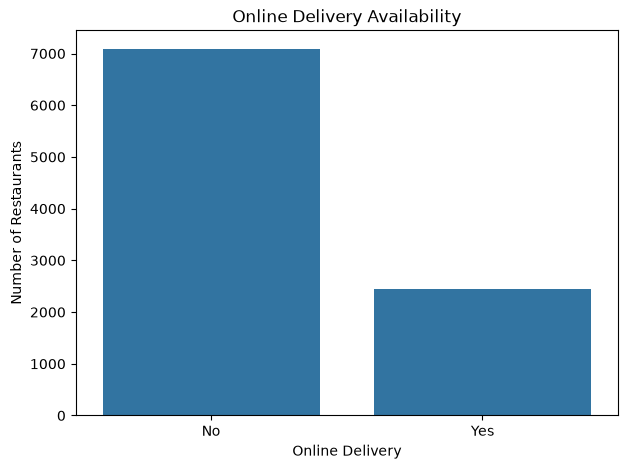

In [45]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values
)

plt.title("Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")

plt.show()

In [46]:
booking_counts = df_clean["Has Table booking"].value_counts()

print(booking_counts)

Has Table booking
No     8384
Yes    1158
Name: count, dtype: int64


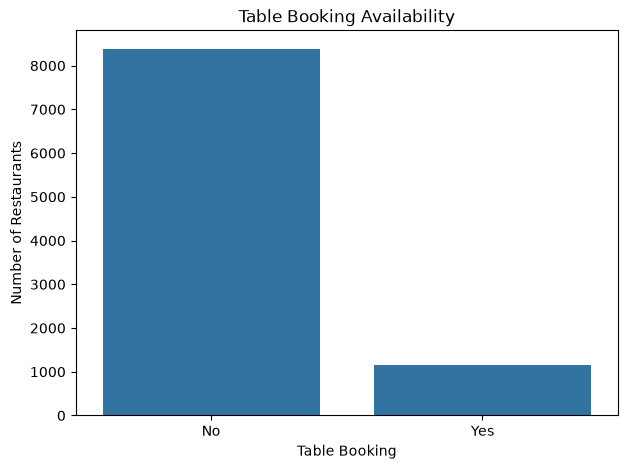

In [47]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=booking_counts.index,
    y=booking_counts.values
)

plt.title("Table Booking Availability")
plt.xlabel("Table Booking")
plt.ylabel("Number of Restaurants")

plt.show()

In [48]:
delivery_rating = df_clean.groupby(
    "Has Online delivery"
)["Aggregate rating"].mean()

print(delivery_rating)

Has Online delivery
No     2.463517
Yes    3.248837
Name: Aggregate rating, dtype: float64


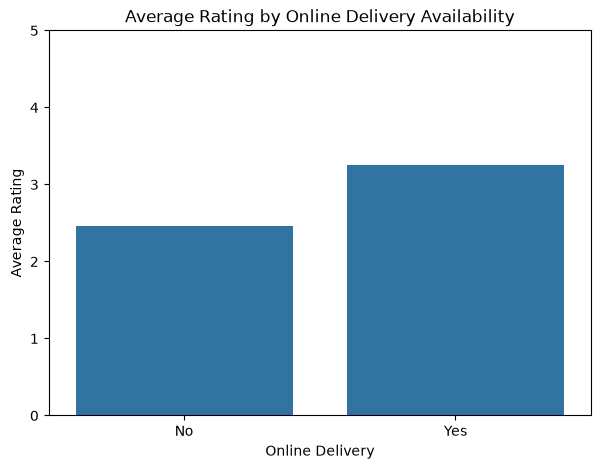

In [49]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=delivery_rating.index,
    y=delivery_rating.values
)

plt.title("Average Rating by Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Average Rating")

plt.ylim(0, 5)

plt.show()

### Online Delivery & Table Booking Insights

1. Most restaurants in the dataset do not offer online delivery. Only 2,451 restaurants offer online delivery compared with 7,091 that do not.

2. Table booking is less common than online delivery, with only 1,158 restaurants offering table booking.

3. Restaurants offering online delivery have a higher average rating (3.25) compared with restaurants without online delivery (2.46).

4. The difference in ratings indicates an association between online delivery availability and restaurant ratings, but it does not establish causation.

5. The findings suggest that digital ordering services may be an important area for further business analysis.

In [50]:
delivery_by_price = pd.crosstab(
    df_india["Price range"],
    df_india["Has Online delivery"],
    normalize="index"
) * 100

print(delivery_by_price.round(2))

Has Online delivery     No    Yes
Price range                      
1                    83.68  16.32
2                    55.18  44.82
3                    64.18  35.82
4                    88.92  11.08


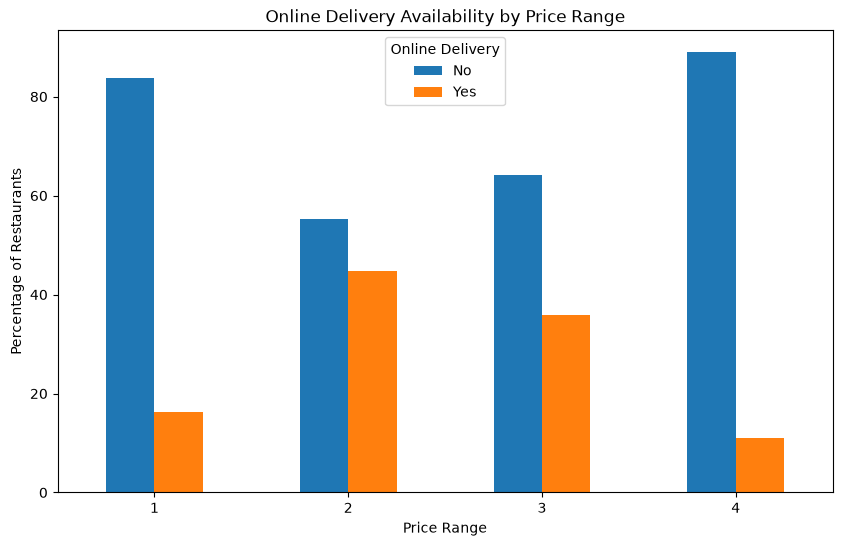

In [51]:
delivery_by_price.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Online Delivery Availability by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Percentage of Restaurants")
plt.xticks(rotation=0)
plt.legend(title="Online Delivery")

plt.show()

### Online Delivery by Price Range Insights

1. Online delivery availability varies considerably across price ranges.

2. Price Range 2 has the highest online delivery adoption at 44.82%.

3. Price Range 3 follows with 35.82% of restaurants offering online delivery.

4. Budget restaurants in Price Range 1 have relatively low online delivery adoption at 16.32%.

5. Premium restaurants in Price Range 4 have the lowest online delivery adoption at 11.08%.

6. The results suggest that online delivery adoption is not directly proportional to restaurant price range.

In [52]:
booking_by_price = pd.crosstab(
    df_india["Price range"],
    df_india["Has Table booking"],
    normalize="index"
) * 100

print(booking_by_price.round(2))

Has Table booking     No    Yes
Price range                    
1                  99.98   0.02
2                  91.78   8.22
3                  43.83  56.17
4                  35.31  64.69


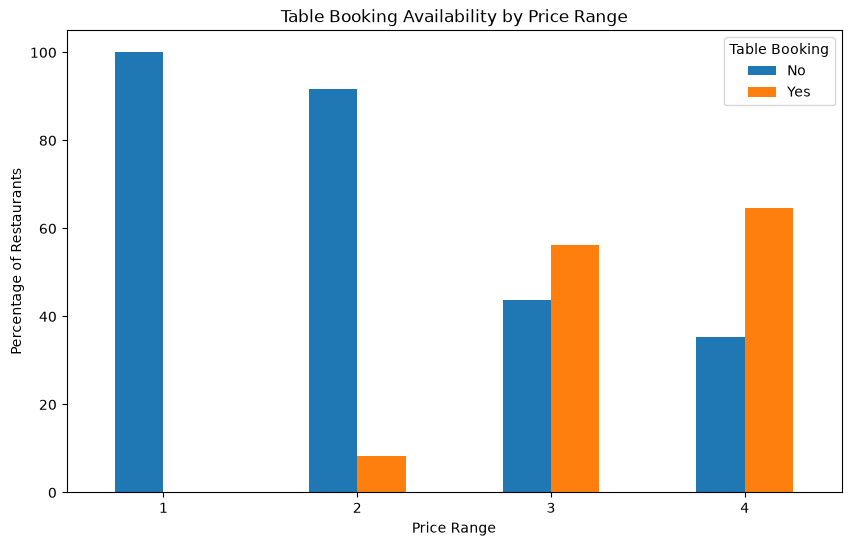

In [53]:
booking_by_price.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Table Booking Availability by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Percentage of Restaurants")
plt.xticks(rotation=0)
plt.legend(title="Table Booking")

plt.show()

### Table Booking by Price Range Insights

1. Table booking availability increases substantially with restaurant price range.

2. Only 0.02% of Price Range 1 restaurants offer table booking, compared with 64.69% of Price Range 4 restaurants.

3. Price Range 3 and Price Range 4 restaurants are much more likely to provide table-booking facilities.

4. The results indicate a strong association between restaurant price range and table-booking availability.

In [54]:
cuisine_stats = df_clean.groupby("Cuisines").agg(
    Restaurant_Count=("Restaurant ID", "count"),
    Average_Rating=("Aggregate rating", "mean")
)

cuisine_stats = cuisine_stats[
    cuisine_stats["Restaurant_Count"] >= 20
].sort_values(
    "Average_Rating",
    ascending=False
).head(10)

print(cuisine_stats.round(2))

                             Restaurant_Count  Average_Rating
Cuisines                                                     
American                                   31            3.67
Italian                                    54            3.66
Italian, Pizza                             24            3.64
Mexican                                    36            3.64
Continental                                21            3.57
Fast Food, Burger                          56            3.40
Cafe, Tea                                  20            3.38
Bakery, Desserts, Fast Food                63            3.37
American, Fast Food                        20            3.35
Chinese, Thai                              51            3.31


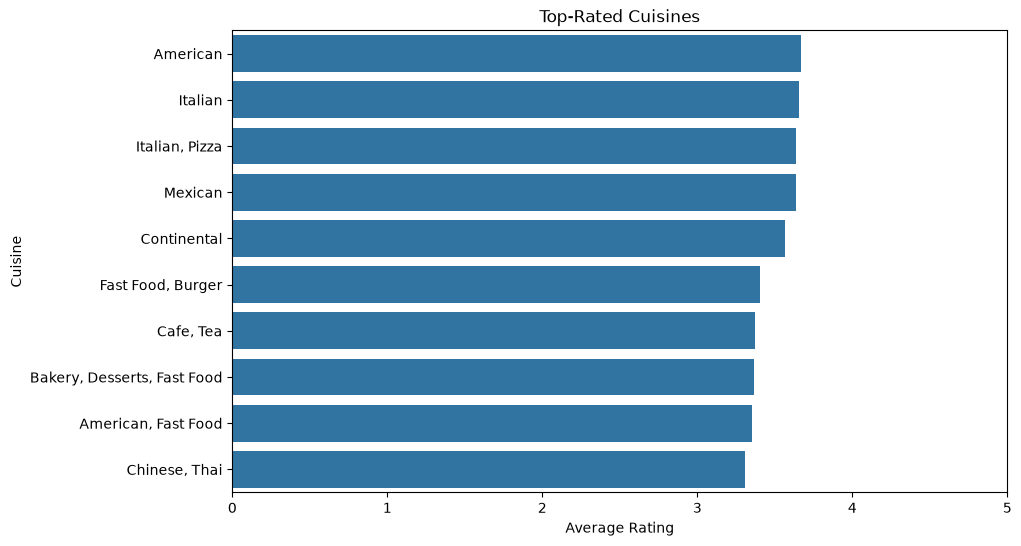

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cuisine_stats.reset_index(),
    x="Average_Rating",
    y="Cuisines"
)

plt.title("Top-Rated Cuisines")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine")
plt.xlim(0, 5)

plt.show()

### Cuisine Rating Insights

1. American cuisine has the highest average rating at 3.67 among cuisines with at least 20 restaurants.

2. Italian cuisine follows closely with an average rating of 3.66.

3. Italian-Pizza and Mexican cuisines also show relatively high average ratings.

4. A minimum restaurant-count threshold of 20 was used to make the comparison more reliable and avoid rankings dominated by cuisines with very few restaurants.

5. The results describe patterns in this dataset and should not be interpreted as a global ranking of cuisines.

In [56]:
correlation_matrix = df_india[
    [
        "Average Cost for two",
        "Price range",
        "Aggregate rating",
        "Votes"
    ]
].corr()

print(correlation_matrix.round(2))

                      Average Cost for two  Price range  Aggregate rating  \
Average Cost for two                  1.00         0.84              0.34   
Price range                           0.84         1.00              0.41   
Aggregate rating                      0.34         0.41              1.00   
Votes                                 0.28         0.31              0.29   

                      Votes  
Average Cost for two   0.28  
Price range            0.31  
Aggregate rating       0.29  
Votes                  1.00  


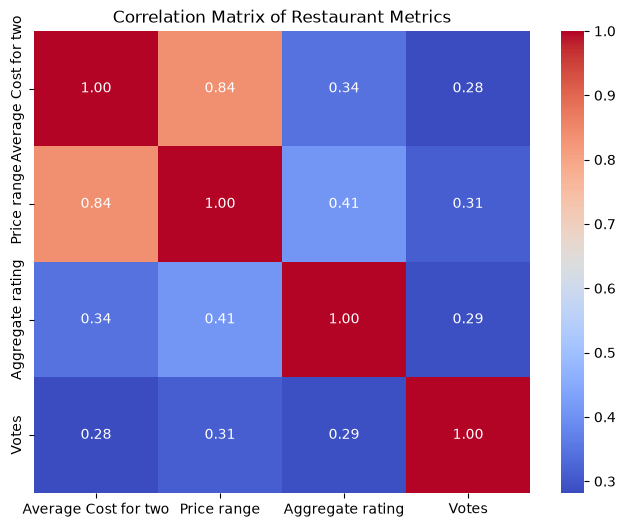

In [57]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Restaurant Metrics")

plt.show()

### Correlation Analysis Insights

1. Average Cost for Two and Price Range have the strongest positive correlation (0.84), indicating that higher price categories are strongly associated with higher restaurant costs.

2. Price Range and Aggregate Rating have a moderate positive correlation (0.41), suggesting that higher-priced restaurants tend to receive somewhat higher ratings.

3. Average Cost for Two and Aggregate Rating have a weaker positive correlation (0.34).

4. Votes and Aggregate Rating have a weak positive correlation, indicating that customer engagement has only a limited linear relationship with restaurant ratings.

5. Correlation measures association and does not establish causation.